# Travel Reimbursement Approval Agent

A lightweight **agentic** prototype: a Gemini function-calling agent reviews travel claims against the policy in Appendix A, using policy-lookup and rule-check tools, and returns a structured recommendation (`APPROVE`, `PARTIAL_APPROVE`, `REJECT`, `MANUAL_REVIEW`).

**Core idea:** the LLM *decides which tools to call and writes the reasoning*; **all money math and policy gating is deterministic code**. A guardrail layer can only *escalate* an LLM decision to Manual Review, never silently override a rule or invent an amount.

## README

**Setup**
1. Python 3.10+ and Jupyter (or Google Colab).
2. Get a free Gemini API key from Google AI Studio.
3. Set the environment variable before launching Jupyter:
   - `GEMINI_API_KEY` (required for LLM mode; `GOOGLE_API_KEY` also works; in Colab, add it as a Secret named `GEMINI_API_KEY`)
   - `GEMINI_MODEL` (optional, default `gemini-2.5-flash`)
4. The first code cell installs `google-genai pandas matplotlib ipywidgets`.

**Run:** `Kernel -> Restart & Run All`. No manual steps are needed.

**Modes**
- `LLM_AGENT` (key present): Gemini drives the tool-calling loop; guardrails verify it.
- `RULES_ONLY` (no key / SDK missing / API failure): the same tools run in a fixed scripted order and explanations come from templates. The notebook still runs end to end, so a reviewer without a key can see every output. Each result's audit trail shows which mode produced it.

**Notebook map:** policy and limits -> sample claims -> tools -> agent loop and guardrails -> run the 5 claims -> sample outputs and audit trail -> tests -> Dashboard -> Design Notes -> final JSON.

**Key design choices** (details in *Design Notes & Reasoning*): deterministic tools own the numbers; retrieval over tagged policy rules (swap for FAISS/Chroma at scale); asymmetric guardrail (LLM can escalate to Manual Review, never relax); schema validation with fallback to Manual Review; full audit trail per claim.

In [28]:
%pip install -q google-genai pandas matplotlib ipywidgets

In [29]:
import os, re, json, time, copy
os.environ["GEMINI_MODEL"] = "gemini-3.1-flash-lite"
from datetime import date
from types import SimpleNamespace

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

try:
    from google import genai
    from google.genai import types
except ImportError:  # SDK missing -> RULES_ONLY mode
    genai, types = None, None

API_KEY = os.environ.get("GEMINI_API_KEY") or os.environ.get("GOOGLE_API_KEY")
if not API_KEY:
    try:  # Colab secrets
        from google.colab import userdata
        API_KEY = userdata.get("GEMINI_API_KEY")
    except Exception:
        pass

MODEL = os.environ.get("GEMINI_MODEL", "gemini-2.5-flash")
MODE = "LLM_AGENT" if (API_KEY and genai) else "RULES_ONLY"
CLIENT = genai.Client(api_key=API_KEY) if MODE == "LLM_AGENT" else None
print(f"Mode: {MODE}" + (f"  |  model: {MODEL}" if MODE == "LLM_AGENT" else "  |  (set GEMINI_API_KEY to enable the Gemini agent)"))

Mode: LLM_AGENT  |  model: gemini-3.1-flash-lite


## 1. Policy and limits (Appendix A)
Every rule has a stable `POL-*` id. `keywords` are retrieval tags used by `lookup_policy`.

In [30]:
POLICY = [
    {"id": "POL-CAT-01", "title": "Eligible categories",
     "text": "Reimbursable when incurred for a documented business purpose: airfare (economy class only, see POL-AIR-01), lodging (hotel room charges), meals (subject to per-diem, see POL-PD-01), ground transport (taxi, rideshare, train, rental car, parking), conference / registration fees.",
     "keywords": ["eligible", "category", "airfare", "lodging", "meals", "ground", "transport", "taxi", "rideshare", "train", "rental", "parking", "conference", "registration", "fees"]},
    {"id": "POL-CAT-02", "title": "Ineligible items",
     "text": "Never reimbursable; rejected (deducted in full): alcohol and minibar charges; spa, gym and personal entertainment; in-room movies, personal shopping, gifts; traffic fines, penalties and late fees; any personal (non-business) expense.",
     "keywords": ["ineligible", "alcohol", "minibar", "spa", "gym", "entertainment", "movies", "shopping", "gifts", "fines", "penalties", "personal", "reject"]},
    {"id": "POL-PD-01", "title": "Meals per-diem",
     "text": "Maximum $75 per day. Amounts above the daily cap are deducted; the rest is reimbursed.",
     "keywords": ["meals", "meal", "dinner", "lunch", "breakfast", "food", "per-diem", "diem", "daily", "cap", "75"]},
    {"id": "POL-PD-02", "title": "Lodging nightly cap",
     "text": "Maximum $200 per night. Amounts above the nightly cap are deducted; the rest is reimbursed.",
     "keywords": ["lodging", "hotel", "night", "nightly", "room", "cap", "200"]},
    {"id": "POL-PD-03", "title": "Ground transport daily cap",
     "text": "Maximum $50 per day. Amounts above the cap are deducted.",
     "keywords": ["ground", "transport", "taxi", "rideshare", "train", "rental", "car", "parking", "daily", "cap", "50"]},
    {"id": "POL-AIR-01", "title": "Airfare class",
     "text": "Only economy class airfare is reimbursable. Business/first-class fares are a policy exception and must be routed to Manual Review (not auto-deducted, because a pre-approval may exist).",
     "keywords": ["airfare", "flight", "air", "class", "economy", "business", "first", "premium", "exception", "pre-approval"]},
    {"id": "POL-RCT-01", "title": "Receipt required above $25",
     "text": "Any single line item greater than $25 requires an attached, itemized receipt. Airfare and lodging always require a receipt regardless of amount.",
     "keywords": ["receipt", "receipts", "itemized", "attached", "documentation", "25", "missing"]},
    {"id": "POL-RCT-02", "title": "Missing receipt handling",
     "text": "If a receipt is missing for an item that requires one, the item is not silently rejected; the claim is routed to Manual Review so the reviewer can request the receipt.",
     "keywords": ["receipt", "missing", "manual", "review", "request"]},
    {"id": "POL-APR-01", "title": "Auto-approve tier",
     "text": "Total reimbursable amount <= $500 (after per-diem deductions, before final decision) may be auto-approved by the agent if fully compliant.",
     "keywords": ["approval", "threshold", "tier", "auto", "approve", "total", "500"]},
    {"id": "POL-APR-02", "title": "Manager tier",
     "text": "Total reimbursable amount > $500 and <= $2,000: eligible for approval, treated as approvable when fully compliant.",
     "keywords": ["approval", "threshold", "tier", "manager", "total", "2000", "500"]},
    {"id": "POL-APR-03", "title": "Director / Manual-Review tier",
     "text": "Total reimbursable amount > $2,000 exceeds the agent's auto-approval authority and must be routed to Manual Review (director approval required), even if otherwise compliant.",
     "keywords": ["approval", "threshold", "tier", "director", "high", "value", "total", "2000", "manual", "review"]},
    {"id": "POL-TIME-01", "title": "Submission window",
     "text": "Claims must be submitted within 30 days of the expense date. Late claims are routed to Manual Review.",
     "keywords": ["timeliness", "late", "submission", "window", "days", "deadline", "30", "submitted"]},
]
POLICY_IDS = {r["id"] for r in POLICY}

LIMITS = {"meals_per_day": 75.0, "lodging_per_night": 200.0, "ground_per_day": 50.0,
          "receipt_threshold": 25.0, "auto_approve_max": 500.0, "manager_max": 2000.0,
          "submission_window_days": 30}

CATEGORY_ALIASES = {"conference": "conference_fees", "registration": "conference_fees",
                    "ground": "ground_transport", "taxi": "ground_transport", "rideshare": "ground_transport",
                    "train": "ground_transport", "rental_car": "ground_transport", "parking": "ground_transport",
                    "hotel": "lodging", "flight": "airfare", "meal": "meals"}
ELIGIBLE = {"airfare", "lodging", "meals", "ground_transport", "conference_fees"}
INELIGIBLE = {"alcohol", "minibar", "spa", "gym", "entertainment", "movies", "shopping", "gifts",
              "fines", "penalties", "late_fees", "personal"}
ALWAYS_RECEIPT = {"airfare", "lodging"}

## 2. Claim intake (Appendix B)
The five sample claims are entered verbatim from Appendix B. `normalize_claim` is the intake step: it validates the JSON, canonicalises categories and extracts structure from free-text descriptions (days / nights, number of attendees) so the tools never have to guess.

In [31]:
RAW_CLAIMS = [
    {"claim_id": "CLM-001", "title": "Attend 2-day industry conference (business)", "employee": "A. Rivera",
     "trip_start": "2026-06-10", "trip_end": "2026-06-12", "submitted": "2026-06-20", "total_claimed": 1110.00,
     "items": [
         {"category": "airfare", "description": "Round-trip economy airfare", "amount": 420.00, "receipt": True},
         {"category": "lodging", "description": "Hotel, 2 nights @ $180", "amount": 360.00, "receipt": True},
         {"category": "meals", "description": "Meals, 3 days @ ~$60/day", "amount": 180.00, "receipt": True},
         {"category": "conference_fees", "description": "Conference registration", "amount": 150.00, "receipt": True}]},
    {"claim_id": "CLM-002", "title": "Weekend hotel stay", "employee": "B. Osei",
     "trip_start": "2026-06-14", "trip_end": "2026-06-15", "submitted": "2026-06-25", "total_claimed": 380.00,
     "items": [
         {"category": "spa", "description": "Hotel spa package", "amount": 300.00, "receipt": True},
         {"category": "minibar", "description": "In-room minibar", "amount": 80.00, "receipt": True}]},
    {"claim_id": "CLM-003", "title": "Client site visit (business)", "employee": "C. Nakamura",
     "trip_start": "2026-06-08", "trip_end": "2026-06-10", "submitted": "2026-06-22", "total_claimed": 940.00,
     "items": [
         {"category": "airfare", "description": "Round-trip economy airfare", "amount": 300.00, "receipt": True},
         {"category": "lodging", "description": "Hotel, 2 nights @ $250", "amount": 500.00, "receipt": True},
         {"category": "meals", "description": "Meals, 2 days @ $70/day", "amount": 140.00, "receipt": True}]},
    {"claim_id": "CLM-004", "title": "International vendor negotiation (business)", "employee": "D. Fischer",
     "trip_start": "2026-06-16", "trip_end": "2026-06-18", "submitted": "2026-06-28", "total_claimed": 3000.00,
     "items": [
         {"category": "airfare", "description": "Business-class international airfare", "amount": 2400.00, "receipt": True},
         {"category": "lodging", "description": "Hotel, 3 nights", "amount": 600.00, "receipt": False}]},
    {"claim_id": "CLM-005", "title": "Client dinner / business development", "employee": "E. Haddad",
     "trip_start": "2026-06-11", "trip_end": "2026-06-11", "submitted": "2026-06-24", "total_claimed": 220.00,
     "items": [
         {"category": "meals", "description": "Client dinner for 4 (business development)", "amount": 220.00, "receipt": False}]},
]
SAMPLE_IDS = [c["claim_id"] for c in RAW_CLAIMS]
CLAIMS = {}  # normalized claim store, keyed by claim_id


def normalize_claim(raw: dict) -> dict:
    """Validate raw claim JSON and return a normalized claim. Raises ValueError on bad input."""
    required = ["claim_id", "employee", "trip_start", "trip_end", "submitted", "items"]
    missing = [k for k in required if k not in raw]
    if missing:
        raise ValueError(f"claim is missing required fields: {missing}")
    try:
        start, end, sub = (date.fromisoformat(raw[k]) for k in ("trip_start", "trip_end", "submitted"))
    except ValueError as e:
        raise ValueError(f"dates must be ISO format YYYY-MM-DD ({e})")
    if end < start:
        raise ValueError("trip_end is before trip_start")
    if not raw["items"]:
        raise ValueError("claim has no items")
    trip_days = (end - start).days + 1
    trip_nights = trip_days - 1
    items = []
    for i, it in enumerate(raw["items"]):
        for k in ("category", "description", "amount", "receipt"):
            if k not in it:
                raise ValueError(f"item {i} is missing '{k}'")
        if float(it["amount"]) < 0:
            raise ValueError(f"item {i} has a negative amount")
        cat = str(it["category"]).strip().lower().replace(" ", "_")
        cat = CATEGORY_ALIASES.get(cat, cat)
        desc = it["description"]
        m = re.search(r"(\d+)\s*(night|day)s?", desc, re.I)
        if m:
            qty, unit, qty_src = int(m.group(1)), m.group(2).lower() + "s", "description"
        elif cat == "lodging":
            qty, unit, qty_src = max(trip_nights, 1), "nights", "trip_dates"
        else:
            qty, unit, qty_src = max(trip_days, 1), "days", "trip_dates"
        att = re.search(r"\bfor\s+(\d+)\b", desc, re.I) if cat == "meals" else None
        items.append({"idx": i, "category": cat, "description": desc, "amount": round(float(it["amount"]), 2),
                      "receipt": bool(it["receipt"]), "qty": qty, "unit": unit, "qty_source": qty_src,
                      "attendees": int(att.group(1)) if att else 1})
    return {"claim_id": raw["claim_id"], "title": raw.get("title", ""), "employee": raw["employee"],
            "trip_start": raw["trip_start"], "trip_end": raw["trip_end"], "submitted": raw["submitted"],
            "trip_days": trip_days, "trip_nights": trip_nights,
            "total_claimed": raw.get("total_claimed"), "items": items}


def register_claim(raw: dict) -> str:
    c = normalize_claim(raw)
    CLAIMS[c["claim_id"]] = c
    return c["claim_id"]


for _raw in RAW_CLAIMS:
    register_claim(_raw)
pd.DataFrame([{"claim_id": c["claim_id"], "employee": c["employee"], "items": len(c["items"]),
               "total_claimed": c["total_claimed"], "trip": f'{c["trip_start"]} -> {c["trip_end"]}'}
              for c in CLAIMS.values()])

,claim_id,employee,items,total_claimed,trip
0,CLM-001,A. Rivera,4,1110.0,2026-06-10 -> 2026-06-12
1,CLM-002,B. Osei,2,380.0,2026-06-14 -> 2026-06-15
2,CLM-003,C. Nakamura,3,940.0,2026-06-08 -> 2026-06-10
3,CLM-004,D. Fischer,2,3000.0,2026-06-16 -> 2026-06-18
4,CLM-005,E. Haddad,1,220.0,2026-06-11 -> 2026-06-11


## 3. Tools
Seven tools. All take a `claim_id` (the agent never retypes claim data, so it cannot mis-copy an amount) and return JSON-serialisable dicts with the policy ids they relied on. The agent calls them via Gemini function calling; `validate_output` is run by the pipeline after the decision.

In [32]:
_STOP = {"the", "a", "an", "of", "for", "and", "or", "to", "is", "are", "in", "on", "per", "any", "be", "than", "with", "what", "does", "if"}


def _tok(s):
    out = []
    for t in re.findall(r"[a-z0-9]+", s.lower()):
        if t in _STOP:
            continue
        if len(t) > 3 and t.endswith("s") and not t.endswith("ss"):
            t = t[:-1]
        out.append(t)
    return out


def _claim(claim_id):
    if claim_id not in CLAIMS:
        raise KeyError(f"unknown claim_id '{claim_id}'")
    return CLAIMS[claim_id]


def lookup_policy(query: str) -> dict:
    """Search the travel reimbursement policy and return the most relevant rules (with their POL-* ids).
    Use this BEFORE deciding, e.g. 'business class airfare', 'receipt required', 'late submission', 'spa'.

    Args:
        query: Short natural-language description of the topic to look up.
    """
    q = set(_tok(query))
    scored = []
    for r in POLICY:
        doc = set(_tok(r["title"] + " " + r["text"]))
        kw = set(_tok(" ".join(r["keywords"])))
        score = len(q & doc) + 2 * len(q & kw)
        if score:
            scored.append((score, r))
    scored.sort(key=lambda x: (-x[0], x[1]["id"]))
    return {"query": query, "matches": [{"id": r["id"], "title": r["title"], "text": r["text"], "score": s}
                                        for s, r in scored[:3]]}


def check_eligibility(claim_id: str) -> dict:
    """Classify each line item as eligible (POL-CAT-01), ineligible (POL-CAT-02) or unknown category.

    Args:
        claim_id: The claim to check, e.g. 'CLM-001'.
    """
    c = _claim(claim_id)
    elig, inel, unknown = [], [], []
    for it in c["items"]:
        row = {"category": it["category"], "amount": it["amount"], "description": it["description"]}
        (elig if it["category"] in ELIGIBLE else inel if it["category"] in INELIGIBLE else unknown).append(row)
    return {"claim_id": claim_id, "eligible_items": elig, "ineligible_items": inel, "unknown_items": unknown,
            "eligible_total": round(sum(i["amount"] for i in elig), 2),
            "ineligible_total": round(sum(i["amount"] for i in inel), 2),
            "refs": (["POL-CAT-01"] if elig else []) + (["POL-CAT-02"] if inel else [])}


def check_receipts(claim_id: str) -> dict:
    """Check receipt completeness: any item > $25 needs a receipt; airfare and lodging always do (POL-RCT-01/02).

    Args:
        claim_id: The claim to check.
    """
    c = _claim(claim_id)
    required, missing = [], []
    for it in c["items"]:
        if it["category"] in INELIGIBLE:
            continue  # never reimbursable, receipt irrelevant
        if it["amount"] > LIMITS["receipt_threshold"] or it["category"] in ALWAYS_RECEIPT:
            required.append(it["category"])
            if not it["receipt"]:
                missing.append(f'itemized receipt for {it["category"]} (${it["amount"]:,.2f})')
    refs = (["POL-RCT-01"] if required else []) + (["POL-RCT-02"] if missing else [])
    return {"claim_id": claim_id, "receipts_required_for": required, "missing_docs": missing, "refs": refs}


def check_limits(claim_id: str) -> dict:
    """Apply per-diem / category limits to eligible items and compute the allowed amount and excess for each line.
    Also flags premium-class airfare (POL-AIR-01) and conflicts between claimed days/nights and the trip dates.

    Args:
        claim_id: The claim to check.
    """
    c = _claim(claim_id)
    lines, exceptions, conflicts, refs = [], [], [], set()
    for it in c["items"]:
        cat, amt = it["category"], it["amount"]
        if cat not in ELIGIBLE:
            continue
        cap, ref = None, None
        if cat == "meals":
            cap, ref = LIMITS["meals_per_day"] * it["qty"], "POL-PD-01"
            if it["qty"] > c["trip_days"]:
                conflicts.append(f'meals claimed for {it["qty"]} days but the trip spans {c["trip_days"]}')
            if it["attendees"] > 1:
                exceptions.append({"code": "MULTI_ATTENDEE_MEAL", "ref": "POL-PD-01",
                                   "msg": f'meal covers {it["attendees"]} people (client dinner); the $75/day per-diem is per employee, so the cap cannot be applied mechanically'})
        elif cat == "lodging":
            cap, ref = LIMITS["lodging_per_night"] * it["qty"], "POL-PD-02"
            if it["qty"] > c["trip_nights"]:
                conflicts.append(f'lodging claimed for {it["qty"]} nights but the trip dates allow {c["trip_nights"]}')
        elif cat == "ground_transport":
            cap, ref = LIMITS["ground_per_day"] * it["qty"], "POL-PD-03"
            if it["qty"] > c["trip_days"]:
                conflicts.append(f'ground transport claimed for {it["qty"]} days but the trip spans {c["trip_days"]}')
        elif cat == "airfare":
            refs.add("POL-AIR-01")
            d = it["description"].lower()
            if re.search(r"business|first|premium", d):
                exceptions.append({"code": "PREMIUM_AIRFARE", "ref": "POL-AIR-01",
                                   "msg": "business/first-class airfare is a policy exception that needs pre-approval verification"})
            elif "economy" not in d and "coach" not in d:
                exceptions.append({"code": "AIRFARE_CLASS_UNSPECIFIED", "ref": "POL-AIR-01",
                                   "msg": "airfare class is not stated, so economy-only eligibility cannot be confirmed"})
        allowed = amt if cap is None else min(amt, cap)
        if ref:
            refs.add(ref)
        lines.append({"category": cat, "claimed": amt, "qty": it["qty"], "unit": it["unit"],
                      "cap": cap, "allowed": round(allowed, 2), "excess": round(amt - allowed, 2), "ref": ref})
    return {"claim_id": claim_id, "lines": lines, "allowed_total": round(sum(l["allowed"] for l in lines), 2),
            "total_excess": round(sum(l["excess"] for l in lines), 2),
            "exceptions": exceptions, "conflicts": conflicts, "refs": sorted(refs)}


def check_timeliness(claim_id: str) -> dict:
    """Check the 30-day submission window (POL-TIME-01), measured from the earliest expense date (trip start).

    Args:
        claim_id: The claim to check.
    """
    c = _claim(claim_id)
    days = (date.fromisoformat(c["submitted"]) - date.fromisoformat(c["trip_start"])).days
    return {"claim_id": claim_id, "days_since_expense": days, "window_days": LIMITS["submission_window_days"],
            "late": days > LIMITS["submission_window_days"], "date_conflict": days < 0,
            "refs": ["POL-TIME-01"] if days > LIMITS["submission_window_days"] else []}


def check_approval_tier(claim_id: str) -> dict:
    """Determine the approval tier from the total reimbursable amount after per-diem deductions (POL-APR-01/02/03).

    Args:
        claim_id: The claim to check.
    """
    total = check_limits(claim_id)["allowed_total"]
    if total <= 0:
        return {"claim_id": claim_id, "reimbursable_total": 0.0, "tier": "NONE", "agent_can_approve": False, "refs": []}
    if total <= LIMITS["auto_approve_max"]:
        tier, ref, ok = "AUTO_APPROVE", "POL-APR-01", True
    elif total <= LIMITS["manager_max"]:
        tier, ref, ok = "MANAGER", "POL-APR-02", True
    else:
        tier, ref, ok = "DIRECTOR_MANUAL_REVIEW", "POL-APR-03", False
    return {"claim_id": claim_id, "reimbursable_total": total, "tier": tier, "agent_can_approve": ok, "refs": [ref]}


def detect_duplicates(claim_id: str) -> dict:
    """Look for a possible duplicate: another claim by the same employee with the same category+amount and overlapping trip dates.

    Args:
        claim_id: The claim to check.
    """
    c = _claim(claim_id)
    s, e = date.fromisoformat(c["trip_start"]), date.fromisoformat(c["trip_end"])
    hits = []
    for o in CLAIMS.values():
        if o["claim_id"] == claim_id or o["employee"] != c["employee"]:
            continue
        os_, oe = date.fromisoformat(o["trip_start"]), date.fromisoformat(o["trip_end"])
        if os_ > e or oe < s:
            continue
        for it in c["items"]:
            if any(x["category"] == it["category"] and x["amount"] == it["amount"] for x in o["items"]):
                hits.append({"other_claim": o["claim_id"], "category": it["category"], "amount": it["amount"]})
    return {"claim_id": claim_id, "possible_duplicates": hits, "refs": []}


def submit_decision(claim_id: str, decision: str, confidence: float, explanation: str, policy_refs: list[str]) -> dict:
    """Submit the FINAL recommendation once all checks are done. Do not include arithmetic of your own: amounts are
    computed by the system from the tool results.

    Args:
        claim_id: The claim being decided.
        decision: One of APPROVE, PARTIAL_APPROVE, REJECT, MANUAL_REVIEW.
        confidence: Your confidence from 0.0 to 1.0.
        explanation: 2-4 sentences grounded in the tool results; cite POL-* ids and only use dollar figures returned by tools.
        policy_refs: The POL-* ids that support the decision.
    """
    return {"status": "received", "claim_id": claim_id}


TOOL_REGISTRY = {f.__name__: f for f in (lookup_policy, check_eligibility, check_receipts, check_limits,
                                         check_timeliness, check_approval_tier, detect_duplicates, submit_decision)}
AGENT_TOOLS = list(TOOL_REGISTRY.values())
print("tools:", list(TOOL_REGISTRY))

tools: ['lookup_policy', 'check_eligibility', 'check_receipts', 'check_limits', 'check_timeliness', 'check_approval_tier', 'detect_duplicates', 'submit_decision']


## 4. Deterministic policy engine, guardrails and validator
`decide()` composes the tool outputs into a decision using the rules in *Decision Guidance*. It is the source of truth for **amounts**. The LLM's proposal is reconciled against it:

| LLM proposal vs policy engine | Outcome |
|---|---|
| Same decision | accepted |
| LLM says `MANUAL_REVIEW`, engine says otherwise | accepted (escalation is always safe: *prefer Manual Review*) |
| Any other disagreement | forced to `MANUAL_REVIEW` and logged |
| No / invalid proposal, API failure | policy-engine result, logged |

In [33]:
DECISIONS = ["APPROVE", "PARTIAL_APPROVE", "REJECT", "MANUAL_REVIEW"]
FINAL_FIELDS = ["claim_id", "decision", "approved_amount", "deducted_amount", "missing_docs",
                "policy_refs", "confidence", "explanation", "tools_used"]
TIER_LABEL = {"AUTO_APPROVE": "auto-approve", "MANAGER": "manager", "DIRECTOR_MANUAL_REVIEW": "director", "NONE": "n/a"}


def compute_facts(claim_id):
    return {"eligibility": check_eligibility(claim_id), "receipts": check_receipts(claim_id),
            "limits": check_limits(claim_id), "timeliness": check_timeliness(claim_id),
            "tier": check_approval_tier(claim_id), "duplicates": detect_duplicates(claim_id)}


def decide(claim_id):
    """Pure, deterministic policy engine. Returns decision, amounts, refs, reasons and a base confidence."""
    c, f = _claim(claim_id), compute_facts(claim_id)
    el, rc, lim, tm, tier, dup = (f[k] for k in ("eligibility", "receipts", "limits", "timeliness", "tier", "duplicates"))
    claimed = round(sum(i["amount"] for i in c["items"]), 2)
    reasons = []

    def add(code, ref, msg, hard=True):
        reasons.append({"code": code, "ref": ref, "msg": msg, "hard": hard})

    nothing_reimbursable = not el["eligible_items"] and not el["unknown_items"]
    # conflicting information (soft)
    if c["total_claimed"] is not None and abs(claimed - float(c["total_claimed"])) > 0.01:
        add("TOTAL_MISMATCH", None, f'stated total ${float(c["total_claimed"]):,.2f} does not match the line items (${claimed:,.2f})', hard=False)
    if tm["date_conflict"]:
        add("DATE_CONFLICT", "POL-TIME-01", "claim was submitted before the trip started", hard=False)
    if not nothing_reimbursable:
        for u in el["unknown_items"]:
            add("UNKNOWN_CATEGORY", "POL-CAT-01", f'category "{u["category"]}" is not in the policy, so eligibility is unclear', hard=False)
        for ex in lim["exceptions"]:
            add(ex["code"], ex["ref"], ex["msg"], hard=ex["code"] == "PREMIUM_AIRFARE")
        for msg in lim["conflicts"]:
            add("QUANTITY_CONFLICT", None, msg, hard=False)
        if rc["missing_docs"]:
            add("MISSING_RECEIPT", "POL-RCT-02", "required receipt missing: " + "; ".join(rc["missing_docs"]) + " (reviewer to request it)")
        if tm["late"]:
            add("LATE_SUBMISSION", "POL-TIME-01", f'submitted {tm["days_since_expense"]} days after the expense date (limit {tm["window_days"]})')
        if tier["tier"] == "DIRECTOR_MANUAL_REVIEW":
            add("OVER_AGENT_AUTHORITY", "POL-APR-03", f'reimbursable total ${tier["reimbursable_total"]:,.2f} exceeds $2,000, so director approval is required')
        if dup["possible_duplicates"]:
            add("POSSIBLE_DUPLICATE", None, "possible duplicate of " + ", ".join(sorted({d["other_claim"] for d in dup["possible_duplicates"]})), hard=False)

    allowed = lim["allowed_total"]
    deducted_if_decided = round(claimed - allowed, 2)
    if nothing_reimbursable:
        decision = "MANUAL_REVIEW" if reasons else "REJECT"  # only soft conflicts can reach here
    elif reasons:
        decision = "MANUAL_REVIEW"
    elif deducted_if_decided > 0:
        decision = "PARTIAL_APPROVE"
    else:
        decision = "APPROVE"

    if decision == "APPROVE":
        approved, deducted, conf = allowed, 0.0, 0.96
    elif decision == "PARTIAL_APPROVE":
        approved, deducted, conf = allowed, deducted_if_decided, 0.94
    elif decision == "REJECT":
        approved, deducted, conf = 0.0, claimed, 0.97
    else:
        approved, deducted = 0.0, 0.0  # nothing is finalised until a human resolves the issues
        conf = 0.90 if any(r["hard"] for r in reasons) else 0.65

    refs = set(el["refs"]) | set(lim["refs"]) | set(rc["refs"]) | set(tm["refs"]) | set(tier["refs"])
    refs |= {r["ref"] for r in reasons if r["ref"]}
    return {"claim_id": claim_id, "decision": decision, "approved_amount": round(approved, 2),
            "deducted_amount": round(deducted, 2), "missing_docs": list(rc["missing_docs"]),
            "policy_refs": sorted(refs), "confidence": conf, "reasons": reasons, "facts": f,
            "claimed_total": claimed, "pre_review_reimbursable": allowed}


def template_explanation(truth, decision=None, note=""):
    d, f, c = decision or truth["decision"], truth["facts"], truth["claimed_total"]
    if d == "APPROVE":
        t = f["tier"]
        s = (f'All items are eligible, required receipts are attached and amounts are within per-diem caps. '
             f'The reimbursable total of ${truth["approved_amount"]:,.2f} falls in the {TIER_LABEL[t["tier"]]} tier ({t["refs"][0]}), so the claim is approved in full.')
    elif d == "PARTIAL_APPROVE":
        parts = [f'{l["category"]} exceeds its cap by ${l["excess"]:,.2f} (claimed ${l["claimed"]:,.2f}, cap ${l["cap"]:,.2f}; {l["ref"]})'
                 for l in f["limits"]["lines"] if l["excess"] > 0]
        parts += [f'{i["category"]} (${i["amount"]:,.2f}) is ineligible under POL-CAT-02' for i in f["eligibility"]["ineligible_items"]]
        s = (f'The claim is valid but {"; ".join(parts)}. Reimbursing ${truth["approved_amount"]:,.2f} and deducting ${truth["deducted_amount"]:,.2f}; '
             f'receipts are complete and the total is within an approvable tier.')
    elif d == "REJECT":
        items = ", ".join(f'{i["category"]} (${i["amount"]:,.2f})' for i in f["eligibility"]["ineligible_items"])
        s = f'Every item is ineligible under POL-CAT-02: {items}. Nothing is reimbursable, so the full ${truth["deducted_amount"]:,.2f} is deducted.'
    else:
        why = "; ".join(f'{r["msg"]}' + (f' ({r["ref"]})' if r["ref"] else "") for r in truth["reasons"]) or "the agent flagged uncertainty that the rules did not catch"
        s = (f'Routed to manual review: {why}. If these are resolved, the pre-review estimate is ${truth["pre_review_reimbursable"]:,.2f} reimbursable '
             f'after per-diem caps; nothing is approved or deducted until a reviewer decides.')
    return (s + " " + note).strip()


def validate_output(r):
    """Output validator: returns a list of error strings (empty = valid)."""
    errs = []
    if list(r.keys()) != FINAL_FIELDS:
        errs.append(f"fields must be exactly {FINAL_FIELDS}")
        return errs
    if r["decision"] not in DECISIONS:
        errs.append("invalid decision")
    for k in ("approved_amount", "deducted_amount"):
        if not isinstance(r[k], (int, float)) or r[k] < 0:
            errs.append(f"{k} must be a non-negative number")
    if not isinstance(r["confidence"], (int, float)) or not 0 <= r["confidence"] <= 1:
        errs.append("confidence must be in [0,1]")
    if not isinstance(r["missing_docs"], list) or not all(isinstance(x, str) for x in r["missing_docs"]):
        errs.append("missing_docs must be a list of strings")
    if not isinstance(r["policy_refs"], list) or not r["policy_refs"] or not set(r["policy_refs"]) <= POLICY_IDS:
        errs.append("policy_refs must be a non-empty list of valid POL-* ids")
    if not isinstance(r["explanation"], str) or len(r["explanation"].strip()) < 20:
        errs.append("explanation is empty/too short")
    if not isinstance(r["tools_used"], list) or not r["tools_used"]:
        errs.append("tools_used must be a non-empty list")
    if r["claim_id"] in CLAIMS and not errs:
        claimed = round(sum(i["amount"] for i in CLAIMS[r["claim_id"]]["items"]), 2)
        if r["decision"] == "MANUAL_REVIEW":
            if r["approved_amount"] or r["deducted_amount"]:
                errs.append("MANUAL_REVIEW must not finalise any amounts")
        elif abs(r["approved_amount"] + r["deducted_amount"] - claimed) > 0.01:
            errs.append("approved + deducted must equal the claimed total")
        if r["decision"] == "APPROVE" and r["deducted_amount"] != 0:
            errs.append("APPROVE cannot have deductions")
        if r["decision"] == "REJECT" and r["approved_amount"] != 0:
            errs.append("REJECT cannot approve any amount")
    return errs


def _allowed_numbers(claim, truth):
    nums = set(LIMITS.values()) | {truth["claimed_total"], truth["approved_amount"], truth["deducted_amount"], truth["pre_review_reimbursable"]}
    for it in claim["items"]:
        nums |= {it["amount"], round(it["amount"] / max(it["qty"], 1), 2), float(it["qty"])}
    for l in truth["facts"]["limits"]["lines"]:
        nums |= {l["claimed"], l["allowed"], l["excess"]} | ({l["cap"]} if l["cap"] is not None else set())
    return {round(float(n), 2) for n in nums}


def explanation_is_grounded(text, claim, truth):
    """Hallucination guard: every $ figure in the LLM explanation must appear in the tool results."""
    ok = _allowed_numbers(claim, truth)
    for m in re.findall(r"\$\s?([\d,]+(?:\.\d+)?)", text):
        if round(float(m.replace(",", "")), 2) not in ok:
            return False, f"${m} does not appear in any tool result"
    return True, ""


def reconcile(claim, truth, proposal):
    """Merge the LLM proposal with the policy-engine result. Returns (result dict without tools_used, guard events)."""
    events, decision = [], truth["decision"]
    explanation, conf, refs, note = None, truth["confidence"], list(truth["policy_refs"]), ""
    if proposal is None:
        events.append("no valid proposal from the agent -> using the policy-engine result")
    else:
        p = proposal["decision"]
        if p == truth["decision"]:
            events.append(f"agent decision {p} matches the policy engine")
        elif p == "MANUAL_REVIEW":
            decision, conf = "MANUAL_REVIEW", min(conf, 0.70)
            events.append(f"agent escalated to MANUAL_REVIEW (engine said {truth['decision']}) -> accepted")
            note = "The agent escalated this claim for human review."
            refs = sorted(set(refs) | (set(proposal["policy_refs"]) & POLICY_IDS))
        else:
            decision, conf = "MANUAL_REVIEW", min(conf, 0.60)
            events.append(f"DISAGREEMENT agent={p} vs engine={truth['decision']} -> forced MANUAL_REVIEW")
            note = f"The agent proposed {p} but the policy engine computed {truth['decision']}; routed for human review."
        if proposal["confidence"] is not None:
            conf = min(conf, proposal["confidence"])
        ok, why = explanation_is_grounded(proposal["explanation"], claim, truth)
        if not proposal["explanation"] or len(proposal["explanation"]) > 1200:
            events.append("agent explanation empty/too long -> template used")
        elif not ok:
            events.append(f"agent explanation rejected ({why}) -> template used")
        elif decision != p:
            events.append("agent explanation discarded because the final decision changed -> template used")
        else:
            explanation = proposal["explanation"].strip()
    if decision == truth["decision"]:
        approved, deducted, missing = truth["approved_amount"], truth["deducted_amount"], truth["missing_docs"]
    else:  # escalated to manual review: nothing finalised
        approved, deducted, missing = 0.0, 0.0, truth["missing_docs"]
    if explanation is None:
        explanation = template_explanation(truth, decision, note)
    return {"claim_id": claim["claim_id"], "decision": decision, "approved_amount": round(approved, 2),
            "deducted_amount": round(deducted, 2), "missing_docs": missing, "policy_refs": refs,
            "confidence": round(conf, 2), "explanation": explanation}, events

## 5. The agent loop (Gemini function calling)
The model receives the claim and a system prompt describing the procedure. It **chooses** which tools to call (it can call several per turn, re-check, or look up the policy for an unusual item), reads the results and finally calls `submit_decision`. Every call and result goes into the audit trail. Tool errors are returned to the model as data so it can recover. `RULES_ONLY` mode replays the same tool sequence deterministically.

In [34]:
SYSTEM_PROMPT = """You are a travel-reimbursement review agent. You review ONE claim at a time against company policy.

Procedure:
1. Call lookup_policy for the topics that matter for this claim (categories, airfare class, receipts, per-diem, timeliness, approval limits).
2. Call the check tools for the claim: check_eligibility, check_receipts, check_limits, check_timeliness, check_approval_tier, detect_duplicates.
3. Combine the results. Never do your own arithmetic: use only the figures the tools return.
4. Call submit_decision exactly once.

Decision rules:
- APPROVE: all items eligible, receipts present, within caps, and the reimbursable total is $2,000 or less. Totals up to $500 are the auto-approve tier and $500.01 to $2,000 are the manager tier; you can approve BOTH. Never escalate just because a total is above $500. Only totals above $2,000 need MANUAL_REVIEW.
- PARTIAL_APPROVE: valid claim but some amounts exceed per-diem caps (excess deducted), or ineligible items sit next to eligible ones.
- REJECT: only ineligible items, nothing reimbursable.
- MANUAL_REVIEW: any ambiguity, policy exception (e.g. business/first class), total above $2,000, missing required receipt, late submission, conflicting or unclear information (for example dates or quantities that do not match, a meal that covers several people, an unknown category). Prefer MANUAL_REVIEW over forcing a decision. Never silently reject for a missing receipt.
Cite only POL-* ids that tools returned. Keep the explanation to 2-4 sentences."""

REQUIRED_AGENT_TOOLS = ["lookup_policy"]


def _llm_call(client, contents, config, retries=3):
    for attempt in range(retries):
        try:
            return client.models.generate_content(model=MODEL, contents=contents, config=config)
        except Exception as e:  # rate limits / transient errors
            if attempt == retries - 1:
                raise
            time.sleep(4 * (attempt + 1) if any(s in str(e) for s in ("429", "RESOURCE_EXHAUSTED", "503", "UNAVAILABLE")) else 1)


def _dispatch(name, args):
    fn = TOOL_REGISTRY.get(name)
    if fn is None:
        return {"error": f"unknown tool '{name}'"}
    try:
        return fn(**args)
    except Exception as e:  # return errors as data so the model can recover
        return {"error": f"{type(e).__name__}: {e}"}


def _parse_proposal(args):
    try:
        d = str(args.get("decision", "")).strip().upper()
        if d not in DECISIONS:
            return None
        conf = args.get("confidence")
        conf = None if conf is None else max(0.0, min(1.0, float(conf)))
        return {"decision": d, "confidence": conf, "explanation": str(args.get("explanation", "")),
                "policy_refs": [str(x) for x in (args.get("policy_refs") or [])]}
    except Exception:
        return None


def run_agent(claim_id, client, max_steps=12):
    """Gemini tool-calling loop. Returns (proposal | None, tools_called, trace)."""
    claim, trace, tools_called, proposal = _claim(claim_id), [], [], None
    prompt = "Review this claim and follow the procedure.\n\n" + json.dumps(
        {k: claim[k] for k in ("claim_id", "title", "employee", "trip_start", "trip_end", "submitted", "total_claimed", "items")}, indent=1)
    contents = [types.Content(role="user", parts=[types.Part(text=prompt)])]
    config = types.GenerateContentConfig(
        system_instruction=SYSTEM_PROMPT, tools=AGENT_TOOLS, temperature=0.0,
        automatic_function_calling=types.AutomaticFunctionCallingConfig(disable=True))
    for step in range(max_steps):
        resp = _llm_call(client, contents, config)
        calls = list(resp.function_calls or [])
        if not calls:
            trace.append({"step": step, "type": "llm_text", "text": (getattr(resp, "text", None) or "")[:300]})
            break
        contents.append(resp.candidates[0].content)
        parts, submitted = [], False
        for fc in calls:
            args = dict(fc.args or {})
            result = _dispatch(fc.name, args)
            tools_called.append(fc.name)
            trace.append({"step": step, "type": "tool_call", "tool": fc.name, "args": args, "result": result})
            parts.append(types.Part.from_function_response(name=fc.name, response={"result": result}))
            if fc.name == "submit_decision" and "error" not in result:
                proposal, submitted = _parse_proposal(args), True
        contents.append(types.Content(role="user", parts=parts))
        if submitted:
            break
    else:
        trace.append({"step": max_steps, "type": "limit", "text": "max steps reached without a decision"})
    return proposal, tools_called, trace


def rules_only_agent(claim_id):
    """Deterministic stand-in for the agent: same tools, fixed order. Used when no LLM is available."""
    claim, trace, called = _claim(claim_id), [], []
    cats = sorted({i["category"] for i in claim["items"]})
    plan = [("lookup_policy", {"query": " ".join(cats) + " receipt per-diem approval"})] + [
        (n, {"claim_id": claim_id}) for n in ("check_eligibility", "check_receipts", "check_limits",
                                               "check_timeliness", "check_approval_tier", "detect_duplicates")]
    for step, (name, args) in enumerate(plan):
        trace.append({"step": step, "type": "tool_call", "tool": name, "args": args, "result": _dispatch(name, args)})
        called.append(name)
    return None, called, trace


def process_claim(claim_id, client=None, use_llm=None):
    """Full pipeline: agent -> harness checks -> reconcile with the policy engine -> validate -> result + audit trail."""
    claim, audit = _claim(claim_id), []
    use_llm = (MODE == "LLM_AGENT") if use_llm is None else use_llm
    client = client or CLIENT
    proposal, tools_called, trace, mode = None, [], [], "RULES_ONLY"
    if use_llm and client is not None:
        try:
            proposal, tools_called, trace = run_agent(claim_id, client)
            mode = "LLM_AGENT"
        except Exception as e:
            audit.append({"type": "fallback", "text": f"LLM call failed ({type(e).__name__}: {str(e)[:120]}) -> RULES_ONLY"})
    if mode == "RULES_ONLY":
        proposal, tools_called, trace = rules_only_agent(claim_id)
    audit.append({"type": "mode", "text": mode})
    audit.extend(trace)
    for t in REQUIRED_AGENT_TOOLS:  # make sure policy context was retrieved
        if t not in tools_called:
            q = " ".join(sorted({i["category"] for i in claim["items"]}))
            audit.append({"type": "harness_tool_call", "tool": t, "args": {"query": q}, "result": lookup_policy(q)})
            tools_called.append(t)
    truth = decide(claim_id)
    audit.append({"type": "policy_engine", "decision": truth["decision"], "approved": truth["approved_amount"],
                  "deducted": truth["deducted_amount"], "reasons": [r["code"] for r in truth["reasons"]]})
    result, events = reconcile(claim, truth, proposal)
    audit.extend({"type": "guardrail", "text": e} for e in events)
    result["tools_used"] = list(dict.fromkeys(tools_called + ["validate_output"]))
    result = {k: result[k] for k in FINAL_FIELDS}
    errs = validate_output(result)
    audit.append({"type": "validate_output", "errors": errs})
    if errs:  # fallback: never emit an invalid object
        audit.append({"type": "guardrail", "text": f"validation failed {errs} -> MANUAL_REVIEW fallback"})
        result.update(decision="MANUAL_REVIEW", approved_amount=0.0, deducted_amount=0.0, confidence=0.5,
                      explanation="Automatic validation failed; routed to manual review. " + "; ".join(errs),
                      policy_refs=result["policy_refs"] if set(result["policy_refs"]) <= POLICY_IDS and result["policy_refs"] else ["POL-RCT-02"])
        result["tools_used"] = list(dict.fromkeys(result["tools_used"]))
    return result, audit

## 6. Run all five claims

In [35]:
RESULTS, AUDIT = [], {}
for cid in SAMPLE_IDS:
    res, aud = process_claim(cid)
    RESULTS.append(res)
    AUDIT[cid] = aud
    if MODE == "LLM_AGENT":
        time.sleep(1)  # be gentle with free-tier rate limits
pd.DataFrame(RESULTS)[["claim_id", "decision", "approved_amount", "deducted_amount", "confidence", "policy_refs"]]

,claim_id,decision,approved_amount,deducted_amount,confidence,policy_refs
0,CLM-001,APPROVE,1110.0,0.0,0.96,"[POL-AIR-01, POL-APR-02, POL-CAT-01, POL-PD-01..."
1,CLM-002,REJECT,0.0,380.0,0.97,[POL-CAT-02]
2,CLM-003,PARTIAL_APPROVE,840.0,100.0,0.94,"[POL-AIR-01, POL-APR-02, POL-CAT-01, POL-PD-01..."
3,CLM-004,MANUAL_REVIEW,0.0,0.0,0.90,"[POL-AIR-01, POL-APR-03, POL-CAT-01, POL-PD-02..."
4,CLM-005,MANUAL_REVIEW,0.0,0.0,0.90,"[POL-APR-01, POL-CAT-01, POL-PD-01, POL-RCT-01..."


## 7. Sample outputs and audit trail
Decision, amounts and explanation for all five claims, then the audit trail (tools called, results and guardrail events) for two of them.

In [36]:
for r in RESULTS:
    print(f'{r["claim_id"]}  {r["decision"]:<16} approved ${r["approved_amount"]:>8,.2f}  deducted ${r["deducted_amount"]:>8,.2f}  conf {r["confidence"]}')
    print(f'   refs: {", ".join(r["policy_refs"])}')
    if r["missing_docs"]:
        print(f'   missing: {r["missing_docs"]}')
    print(f'   {r["explanation"]}\n')


def show_audit(cid, max_len=170):
    print(f"--- audit trail {cid} ---")
    for e in AUDIT[cid]:
        if e["type"] in ("tool_call", "harness_tool_call"):
            res = json.dumps(e["result"], default=str)
            print(f'  [{e["type"]}] {e["tool"]}({json.dumps(e["args"])}) -> {res[:max_len]}{"..." if len(res) > max_len else ""}')
        elif e["type"] == "policy_engine":
            print(f'  [policy_engine] {e["decision"]} approved={e["approved"]} deducted={e["deducted"]} reasons={e["reasons"]}')
        else:
            print(f'  [{e["type"]}] {e.get("text", e.get("errors", ""))}')
    print()


show_audit("CLM-003")
show_audit("CLM-004")

CLM-001  APPROVE          approved $1,110.00  deducted $    0.00  conf 0.96
   refs: POL-AIR-01, POL-APR-02, POL-CAT-01, POL-PD-01, POL-PD-02, POL-RCT-01
   The claim is fully compliant with company policy, with all items eligible under POL-CAT-01 and all required receipts provided per POL-RCT-01. The total amount of $1,110 falls within the manager approval tier (POL-APR-02) and does not exceed any per-diem or category limits (POL-PD-01, POL-PD-02). The submission was made within the 30-day window.

CLM-002  REJECT           approved $    0.00  deducted $  380.00  conf 0.97
   refs: POL-CAT-02
   The claim consists entirely of ineligible items, specifically a spa package and minibar charges, which are not reimbursable under policy POL-CAT-02. As there are no eligible expenses, the claim is rejected in full.

CLM-003  PARTIAL_APPROVE  approved $  840.00  deducted $  100.00  conf 0.94
   refs: POL-AIR-01, POL-APR-02, POL-CAT-01, POL-PD-01, POL-PD-02, POL-RCT-01
   The claim is valid but 

In [37]:
from google import genai
from google.colab import userdata
c = genai.Client(api_key=userdata.get("GEMINI_API_KEY"))
for m in c.models.list():
    if "generateContent" in (m.supported_actions or []):
        print(m.name)

models/gemini-2.5-flash
models/gemini-2.5-pro
models/gemini-2.5-flash-preview-tts
models/gemini-2.5-pro-preview-tts
models/gemma-4-26b-a4b-it
models/gemma-4-31b-it
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-pro-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3-flash-preview
models/gemini-3.1-pro-preview
models/gemini-3.1-pro-preview-customtools
models/gemini-3.1-flash-lite-preview
models/gemini-3.1-flash-lite
models/gemini-3-pro-image-preview
models/gemini-3-pro-image
models/nano-banana-pro-preview
models/gemini-3.1-flash-image-preview
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-nano-banana-2.1
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-omni-1.1-flash
models/gemini-3.5-transcribe
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/gemini-4-argon
models/lyria-3-clip-preview
models/lyria-3-pro-preview
models/l

## 8. Tests
(a) The five provided claims must produce the expected decisions and amounts. (b) Edge-case **unit-test fixtures** (not part of the evaluated claim set; removed afterwards) exercise rules the samples do not hit. (c) The agent loop and guardrails are tested with a **scripted model**, so no API key is needed.

In [38]:
EXPECTED = {"CLM-001": ("APPROVE", 1110.0, 0.0), "CLM-002": ("REJECT", 0.0, 380.0), "CLM-003": ("PARTIAL_APPROVE", 840.0, 100.0),
            "CLM-004": ("MANUAL_REVIEW", 0.0, 0.0), "CLM-005": ("MANUAL_REVIEW", 0.0, 0.0)}
for r in RESULTS:
    exp = EXPECTED[r["claim_id"]]
    got = (r["decision"], r["approved_amount"], r["deducted_amount"])
    if got != exp:
        assert r["decision"] == "MANUAL_REVIEW" and got[1:] == (0.0, 0.0), (r["claim_id"], got, exp)
        print(f'NOTE {r["claim_id"]}: agent escalated to MANUAL_REVIEW (expected {exp[0]}), safe but conservative')
    assert not validate_output(r), r["claim_id"]
assert any("lookup_policy" in r["tools_used"] for r in RESULTS)
print("OK: 5/5 provided claims match expected decisions and amounts")


def _fx(cid, items, start="2026-06-01", end="2026-06-02", submitted="2026-06-05", emp="T. Tester", total=None):
    return {"claim_id": cid, "employee": emp, "trip_start": start, "trip_end": end, "submitted": submitted,
            "total_claimed": total if total is not None else sum(i["amount"] for i in items), "items": items}


FIXTURES = [
    ("_T1", _fx("_T1", [{"category": "airfare", "description": "Economy airfare", "amount": 2100.0, "receipt": True}]), "MANUAL_REVIEW", "over $2,000 tier"),
    ("_T2", _fx("_T2", [{"category": "meals", "description": "Meals, 2 days", "amount": 100.0, "receipt": True}], submitted="2026-07-20"), "MANUAL_REVIEW", "late submission"),
    ("_T3", _fx("_T3", [{"category": "ground_transport", "description": "Taxi, 2 days", "amount": 130.0, "receipt": True}]), "PARTIAL_APPROVE", "ground transport cap"),
    ("_T4", _fx("_T4", [{"category": "meals", "description": "Snack, 1 day", "amount": 20.0, "receipt": False}]), "APPROVE", "no receipt needed <= $25"),
    ("_T5", _fx("_T5", [{"category": "airfare", "description": "First class airfare", "amount": 900.0, "receipt": True}]), "MANUAL_REVIEW", "first class"),
    ("_T6", _fx("_T6", [{"category": "meals", "description": "Meals, 1 day", "amount": 60.0, "receipt": True},
                        {"category": "gifts", "description": "Gift for client", "amount": 40.0, "receipt": True}]), "PARTIAL_APPROVE", "ineligible next to eligible"),
    ("_T7", _fx("_T7", [{"category": "meals", "description": "Meals, 1 day", "amount": 50.0, "receipt": True}], total=70.0), "MANUAL_REVIEW", "stated total conflicts"),
    ("_T8", _fx("_T8", [{"category": "meals", "description": "Meals, 1 day", "amount": 50.0, "receipt": True}], emp="B. Dup"), "MANUAL_REVIEW", "possible duplicate (claim 1 of 2)"),
    ("_T9", _fx("_T9", [{"category": "meals", "description": "Meals, 1 day", "amount": 50.0, "receipt": True}], emp="B. Dup"), "MANUAL_REVIEW", "possible duplicate (claim 2 of 2)"),
]
for cid, raw, _, _ in FIXTURES:
    register_claim(raw)
for cid, raw, want, label in FIXTURES:
    got = decide(cid)["decision"]
    assert got == want, (cid, label, got, want)
    print(f"OK  {label:<34} -> {got}")
for cid, *_ in FIXTURES:
    CLAIMS.pop(cid, None)


# (c) scripted model: lets us test the loop and the guardrails offline
class _ScriptedModels:
    def __init__(self, steps):
        self.steps = list(steps)

    def generate_content(self, model, contents, config):
        step = self.steps.pop(0)
        parts = [types.Part(function_call=types.FunctionCall(name=n, args=a)) for n, a in step]
        return SimpleNamespace(function_calls=[p.function_call for p in parts],
                               candidates=[SimpleNamespace(content=types.Content(role="model", parts=parts))], text=None)


if types is not None:
    good = [[("lookup_policy", {"query": "lodging cap"})],
            [("check_eligibility", {"claim_id": "CLM-003"}), ("check_limits", {"claim_id": "CLM-003"}), ("check_receipts", {"claim_id": "NOPE"})],
            [("check_timeliness", {"claim_id": "CLM-003"}), ("check_approval_tier", {"claim_id": "CLM-003"}), ("detect_duplicates", {"claim_id": "CLM-003"})],
            [("submit_decision", {"claim_id": "CLM-003", "decision": "PARTIAL_APPROVE", "confidence": 0.9, "policy_refs": ["POL-PD-02"],
                                  "explanation": "Lodging at $250/night exceeds the $200 cap (POL-PD-02), so $100.00 is deducted and $840.00 reimbursed."})]]
    r, a = process_claim("CLM-003", client=SimpleNamespace(models=_ScriptedModels(good)), use_llm=True)
    assert r["decision"] == "PARTIAL_APPROVE" and r["approved_amount"] == 840.0 and r["explanation"].startswith("Lodging at $250/night")
    assert any(e["type"] == "tool_call" and "error" in e["result"] for e in a), "tool error should be returned to the model"
    print("OK  agent loop: tool use, error recovery, grounded explanation accepted")

    bad = [[("submit_decision", {"claim_id": "CLM-004", "decision": "APPROVE", "confidence": 0.99, "policy_refs": ["POL-CAT-01"],
                                 "explanation": "Everything looks fine, approving $9,999.00 in full."})]]
    r, a = process_claim("CLM-004", client=SimpleNamespace(models=_ScriptedModels(bad)), use_llm=True)
    assert r["decision"] == "MANUAL_REVIEW" and r["approved_amount"] == 0.0 and "$9,999" not in r["explanation"]
    assert "lookup_policy" in r["tools_used"], "harness must retrieve policy context if the agent skipped it"
    print("OK  guardrails: over-confident APPROVE overridden, hallucinated amount dropped, retrieval enforced")

    esc = [[("submit_decision", {"claim_id": "CLM-001", "decision": "MANUAL_REVIEW", "confidence": 0.6, "policy_refs": ["POL-CAT-01"],
                                 "explanation": "Escalating because the conference purpose is not documented in the claim."})]]
    r, a = process_claim("CLM-001", client=SimpleNamespace(models=_ScriptedModels(esc)), use_llm=True)
    assert r["decision"] == "MANUAL_REVIEW" and r["confidence"] <= 0.6
    print("OK  guardrails: LLM escalation to MANUAL_REVIEW is honoured")

    broken = SimpleNamespace(models=SimpleNamespace(generate_content=lambda **kw: (_ for _ in ()).throw(RuntimeError("503 boom"))))
    _sleep, time.sleep = time.sleep, (lambda s: None)
    r, a = process_claim("CLM-002", client=broken, use_llm=True)
    time.sleep = _sleep
    assert r["decision"] == "REJECT" and any(e["type"] == "fallback" for e in a)
    print("OK  fallback: API failure -> rules-only result, claim still decided")
else:
    print("google-genai not installed: skipping scripted-model tests")

OK: 5/5 provided claims match expected decisions and amounts
OK  over $2,000 tier                   -> MANUAL_REVIEW
OK  late submission                    -> MANUAL_REVIEW
OK  ground transport cap               -> PARTIAL_APPROVE
OK  no receipt needed <= $25           -> APPROVE
OK  first class                        -> MANUAL_REVIEW
OK  ineligible next to eligible        -> PARTIAL_APPROVE
OK  stated total conflicts             -> MANUAL_REVIEW
OK  possible duplicate (claim 1 of 2)  -> MANUAL_REVIEW
OK  possible duplicate (claim 2 of 2)  -> MANUAL_REVIEW
OK  agent loop: tool use, error recovery, grounded explanation accepted
OK  guardrails: over-confident APPROVE overridden, hallucinated amount dropped, retrieval enforced
OK  guardrails: LLM escalation to MANUAL_REVIEW is honoured
OK  fallback: API failure -> rules-only result, claim still decided


In [39]:
r = RESULTS[0]
print(r["decision"], r["approved_amount"], r["deducted_amount"], r["confidence"])
print(r["explanation"])
for e in AUDIT["CLM-001"]:
    if e["type"] in ("mode", "guardrail", "fallback", "policy_engine"):
        print(e)

APPROVE 1110.0 0.0 0.96
The claim is fully compliant with company policy, with all items eligible under POL-CAT-01 and all required receipts provided per POL-RCT-01. The total amount of $1,110 falls within the manager approval tier (POL-APR-02) and does not exceed any per-diem or category limits (POL-PD-01, POL-PD-02). The submission was made within the 30-day window.
{'type': 'mode', 'text': 'LLM_AGENT'}
{'type': 'policy_engine', 'decision': 'APPROVE', 'approved': 1110.0, 'deducted': 0.0, 'reasons': []}
{'type': 'guardrail', 'text': 'agent decision APPROVE matches the policy engine'}


## Dashboard
Everything below is derived from `RESULTS` (the actual claim outcomes). The figure is saved as `UI SS_1.png`. The interactive panel at the bottom lets you pick a sample claim, or paste your own claim JSON, and run the agent.

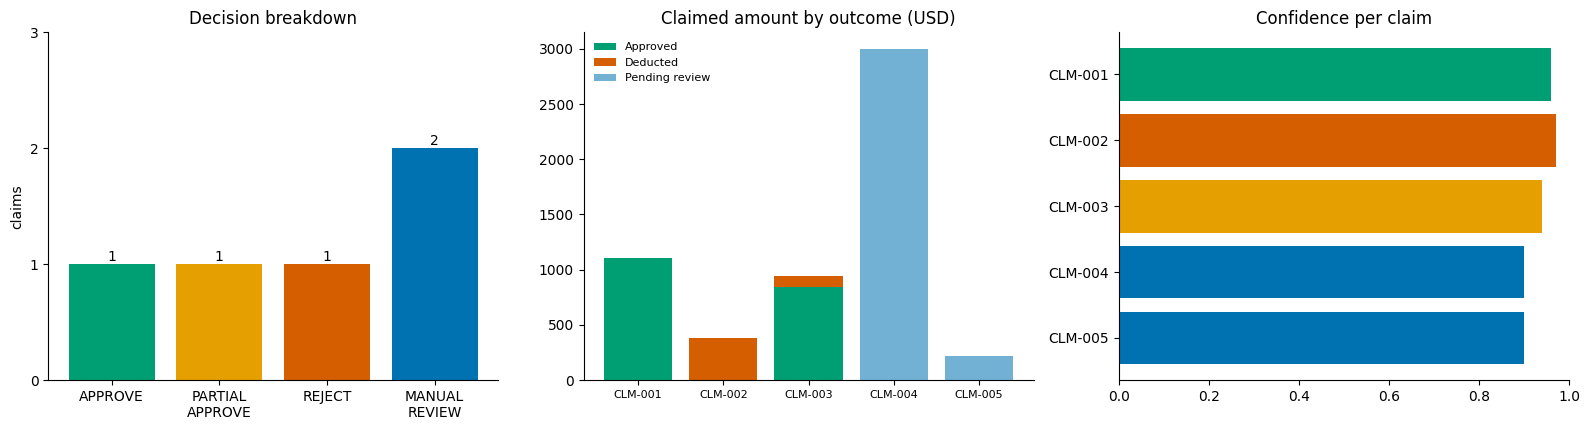

,claim_id,decision,claimed,approved_amount,deducted_amount,pending_review,confidence
0,CLM-001,APPROVE,1110.0,1110.0,0.0,0.0,0.96
1,CLM-002,REJECT,380.0,0.0,380.0,0.0,0.97
2,CLM-003,PARTIAL_APPROVE,940.0,840.0,100.0,0.0,0.94
3,CLM-004,MANUAL_REVIEW,3000.0,0.0,0.0,3000.0,0.90
4,CLM-005,MANUAL_REVIEW,220.0,0.0,0.0,220.0,0.90


In [40]:
df = pd.DataFrame(RESULTS)
claimed = {c["claim_id"]: round(sum(i["amount"] for i in c["items"]), 2) for c in CLAIMS.values()}
df["claimed"] = df["claim_id"].map(claimed)
df["pending_review"] = df.apply(lambda r: r["claimed"] if r["decision"] == "MANUAL_REVIEW" else 0.0, axis=1)

COL = {"APPROVE": "#009E73", "PARTIAL_APPROVE": "#E69F00", "REJECT": "#D55E00", "MANUAL_REVIEW": "#0072B2"}
tot = df[["claimed", "approved_amount", "deducted_amount", "pending_review"]].sum()
auto_rate = (df["decision"] != "MANUAL_REVIEW").mean()


def kpi(label, value):
    return (f'<div style="flex:1;min-width:130px;padding:10px 14px;border:1px solid #d0d7de;border-radius:8px;margin:4px">'
            f'<div style="font-size:12px;color:#57606a">{label}</div><div style="font-size:22px;font-weight:600">{value}</div></div>')


display(HTML('<div style="display:flex;flex-wrap:wrap">' + kpi("Claims", len(df)) + kpi("Total claimed", f"${tot['claimed']:,.0f}")
             + kpi("Approved", f"${tot['approved_amount']:,.0f}") + kpi("Deducted", f"${tot['deducted_amount']:,.0f}")
             + kpi("Pending manual review", f"${tot['pending_review']:,.0f}") + kpi("Auto-decided", f"{auto_rate:.0%}")
             + kpi("Avg confidence", f"{df['confidence'].mean():.2f}") + kpi("Mode", MODE) + '</div>'))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
counts = df["decision"].value_counts().reindex(DECISIONS).fillna(0)
bars = ax[0].bar([d.replace("_", "\n") for d in counts.index], counts.values, color=[COL[d] for d in counts.index])
ax[0].bar_label(bars, fmt="%d")
ax[0].set_title("Decision breakdown"); ax[0].set_ylabel("claims"); ax[0].set_yticks(range(0, int(counts.max()) + 2))

x = range(len(df))
ax[1].bar(x, df["approved_amount"], color="#009E73", label="Approved")
ax[1].bar(x, df["deducted_amount"], bottom=df["approved_amount"], color="#D55E00", label="Deducted")
ax[1].bar(x, df["pending_review"], bottom=df["approved_amount"] + df["deducted_amount"], color="#0072B2", alpha=0.55, label="Pending review")
ax[1].set_xticks(list(x)); ax[1].set_xticklabels(df["claim_id"], rotation=0, fontsize=8)
ax[1].set_title("Claimed amount by outcome (USD)"); ax[1].legend(fontsize=8, frameon=False)

ax[2].barh(df["claim_id"][::-1], df["confidence"][::-1], color=[COL[d] for d in df["decision"][::-1]])
ax[2].set_xlim(0, 1); ax[2].set_title("Confidence per claim")
for a_ in ax:
    a_.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig("UI SS_1.png", dpi=130, bbox_inches="tight")
plt.show()
display(df[["claim_id", "decision", "claimed", "approved_amount", "deducted_amount", "pending_review", "confidence"]])

In [41]:
# Interactive panel: choose a sample claim or paste custom claim JSON, then run the agent.
def render_card(res, audit):
    color = COL[res["decision"]]
    esc = lambda s: str(s).replace("<", "&lt;")
    miss = f'<div><b>Missing docs:</b> {esc("; ".join(res["missing_docs"]))}</div>' if res["missing_docs"] else ""
    tools = " -> ".join(res["tools_used"])
    events = "".join(f'<li>{esc(e["text"])}</li>' for e in audit if e["type"] in ("guardrail", "fallback"))
    return (f'<div style="padding:10px 14px;border:1px solid #d0d7de;border-left:6px solid {color};border-radius:6px;font-family:sans-serif">'
            f'<div style="font-size:18px;font-weight:600;color:{color}">{res["claim_id"]}: {res["decision"]}</div>'
            f'<div>Approved <b>${res["approved_amount"]:,.2f}</b> &nbsp; Deducted <b>${res["deducted_amount"]:,.2f}</b> &nbsp; Confidence <b>{res["confidence"]}</b></div>'
            f'{miss}<div><b>Policy refs:</b> {", ".join(res["policy_refs"])}</div>'
            f'<p>{esc(res["explanation"])}</p><div style="font-size:12px;color:#57606a"><b>Tools:</b> {tools}</div>'
            f'<ul style="font-size:12px;color:#57606a">{events}</ul></div>')


def build_ui():
    import ipywidgets as w
    dd = w.Dropdown(options=SAMPLE_IDS + ["Custom claim (JSON)"], description="Claim:", layout=w.Layout(width="420px"))
    ta = w.Textarea(layout=w.Layout(width="100%", height="230px"))
    btn = w.Button(description="Evaluate claim", button_style="primary", icon="check")
    out = w.Output()
    raw_by_id = {c["claim_id"]: c for c in RAW_CLAIMS}
    cache = {r["claim_id"]: (r, AUDIT[r["claim_id"]]) for r in RESULTS}

    def on_select(_=None):
        if dd.value in raw_by_id:
            ta.value, ta.disabled = json.dumps(raw_by_id[dd.value], indent=1), True
        else:
            tmpl = copy.deepcopy(RAW_CLAIMS[0]); tmpl["claim_id"] = "CLM-CUSTOM"
            ta.value, ta.disabled = json.dumps(tmpl, indent=1), False

    def on_click(_):
        out.clear_output()
        with out:
            try:
                if dd.value in cache:
                    res, aud = cache[dd.value]
                else:
                    cid = register_claim(json.loads(ta.value))
                    res, aud = process_claim(cid)
                display(HTML(render_card(res, aud)))
                show_audit_list(aud)
            except Exception as e:
                display(HTML(f'<div style="color:#D55E00">Invalid claim: {e}</div>'))

    dd.observe(on_select, names="value"); btn.on_click(on_click); on_select()
    return w.VBox([dd, ta, btn, out])


def show_audit_list(aud, max_len=150):
    for e in aud:
        if e["type"] in ("tool_call", "harness_tool_call"):
            res = json.dumps(e["result"], default=str)
            print(f'[{e["tool"]}] {json.dumps(e["args"])} -> {res[:max_len]}{"..." if len(res) > max_len else ""}')
        elif e["type"] == "policy_engine":
            print(f'[policy_engine] {e["decision"]} reasons={e["reasons"]}')


try:
    display(build_ui())
except ImportError:
    print("ipywidgets not available: use process_claim(register_claim(raw_json)) directly.")

## Design Notes & Reasoning

**Architecture.** Gemini is the *orchestrator and writer*; code is the *accountant and gatekeeper*. The LLM picks tools, reads results, flags ambiguity and writes the explanation. Tools compute every figure (per-diem caps, deductions, tier). A deterministic `decide()` engine mirrors the policy's Decision Guidance and owns the amounts; the guardrail can only *escalate* an LLM decision to Manual Review. Because the cost of a wrong auto-approval is higher than a human glance, I made the policy asymmetric on purpose.

**Why not RAG / a framework.** The policy is about 12 short rules, so retrieval is a keyword-scored lookup over tagged rules that returns `POL-*` ids. Pasting the whole policy into the prompt would also work. For a real policy (hundreds of rules, versions, regions) I would swap `lookup_policy` for embeddings in FAISS/Chroma/Azure AI Search with the same interface, plus a rule-version id in the audit trail. I used the plain `google-genai` SDK instead of LangChain/CrewAI because one agent with seven tools does not need an orchestration layer; the loop is about 30 lines and fully inspectable.

**Reliability.** (1) Tools take `claim_id`, so the model never retypes data. (2) Tool errors are returned as data and the model can recover. (3) Retries with backoff on 429/503. (4) A hallucination guard rejects any `$` figure in the LLM's explanation that is not in a tool result. (5) The output validator enforces the schema and the invariant `approved + deducted = claimed` (or 0/0 for Manual Review). (6) Any failure falls back to the policy engine, and a validation failure falls back to Manual Review. (7) The audit trail records every call, result and guardrail event, and `RULES_ONLY` mode keeps the notebook runnable with no key.

**Why these claims go to Manual Review.**
- **CLM-004:** business-class airfare is a policy exception that may have pre-approval (POL-AIR-01); the $600 lodging receipt is missing (POL-RCT-01/02); the total is above $2,000 and needs director approval (POL-APR-03); and 3 nights are claimed for a trip whose dates cover 2 nights (conflicting information). Any one of these is enough.
- **CLM-005:** a $220 meal has no receipt (POL-RCT-02), and it is a client dinner for 4, so the $75/day per-diem (which is per employee) cannot be applied mechanically. I did not auto-deduct the $145 excess because that would force an answer on ambiguous information; the explanation shows the pre-review estimate instead.
- **Decided automatically:** CLM-001 approve (within caps, manager tier), CLM-002 reject (spa and minibar are never reimbursable), CLM-003 partial (lodging $500 vs $400 cap, so $100 deducted, $840 approved).

**Assumptions.**
- Per-diem caps are applied to the aggregate of a category (cap x days or nights) because claims list category totals, not per-day receipts.
- Day and night counts come from the description ("2 nights", "3 days"); otherwise from the trip dates.
- The expense date for the 30-day window is the trip start date (the strictest reading); no sample claim is near the limit.
- For `MANUAL_REVIEW`, `approved_amount` and `deducted_amount` are 0 because nothing is finalised until a human decides.
- `confidence` is the minimum of the engine's base confidence (higher for clear-cut cases, lower where only soft ambiguity triggered review) and the model's own confidence.
- Receipts are metadata flags (attached yes/no); I do not inspect receipt contents.

**Known gaps and what I would improve next.**
- Real receipt checking (vision model on receipt images: date, vendor, amount, itemisation vs the claim).
- Per-day line items so per-diem can be applied exactly, and a per-person rule for client meals.
- A persistent claim ledger for duplicate detection and employee history (instead of the in-memory batch).
- Retrieval over a larger, versioned policy store, and an LLM-as-judge or labelled eval set measured in CI (the tests here are a small smoke suite).
- Tracing/observability (e.g. OpenTelemetry or LangSmith-style spans), PII redaction before prompts, a human-review queue API, and prompt-injection screening of claim descriptions. Descriptions are untrusted text; here they only reach the model as data and cannot change amounts because amounts come from code.

In [42]:
FINAL_OUTPUT = [{k: r[k] for k in FINAL_FIELDS} for r in RESULTS]
assert len(FINAL_OUTPUT) == 5 and all(not validate_output(r) for r in FINAL_OUTPUT)
print(json.dumps(FINAL_OUTPUT, indent=2))

[
  {
    "claim_id": "CLM-001",
    "decision": "APPROVE",
    "approved_amount": 1110.0,
    "deducted_amount": 0.0,
    "missing_docs": [],
    "policy_refs": [
      "POL-AIR-01",
      "POL-APR-02",
      "POL-CAT-01",
      "POL-PD-01",
      "POL-PD-02",
      "POL-RCT-01"
    ],
    "confidence": 0.96,
    "explanation": "The claim is fully compliant with company policy, with all items eligible under POL-CAT-01 and all required receipts provided per POL-RCT-01. The total amount of $1,110 falls within the manager approval tier (POL-APR-02) and does not exceed any per-diem or category limits (POL-PD-01, POL-PD-02). The submission was made within the 30-day window.",
    "tools_used": [
      "lookup_policy",
      "check_eligibility",
      "check_receipts",
      "check_limits",
      "check_timeliness",
      "check_approval_tier",
      "detect_duplicates",
      "submit_decision",
      "validate_output"
    ]
  },
  {
    "claim_id": "CLM-002",
    "decision": "REJECT",
    